# PROBLEM

The telecom company wants to identify customers likely to cancel their service so the retention team can offer targeted incentives before they leave.


*MAIN AIM*
The model should find churners early enough for the company to act, not merely achieve high accuracy.

# code 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

num_rows , num_cols = df.shape
print(f"Rows : {num_rows}, Columns : {num_cols}")

Rows : 7043, Columns : 21


In [2]:
# getting headers
columns = df.columns.tolist()
print(columns)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [3]:
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
# to get data types
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
#getting numberof unique values

print(df.nunique())

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [7]:
uniq_val , index = np.unique(df['Churn'], return_index = True)

print(uniq_val,"\n\n",index)

['No' 'Yes'] 

 [0 2]


In [8]:
#checking for missing values  

print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
print(df['TotalCharges'].dtype)

str


In [10]:
print(df['TotalCharges'].info())

<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype
--------------  -----
7043 non-null   str  
dtypes: str(1)
memory usage: 55.2 KB
None


In [11]:
#to convert data type from string to floating points

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(df['TotalCharges'].dtype)

float64


#Churn analysis by type of data 

# 1. contract type

In [12]:
# hypothesis :

#getting data 

contract_t = df['Contract']

print("Data fields used include : ",df['Contract'].unique())
print("number of unique categories : ",df['Contract'].nunique())

Data fields used include :  <StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
number of unique categories :  3


In [13]:
print(columns)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


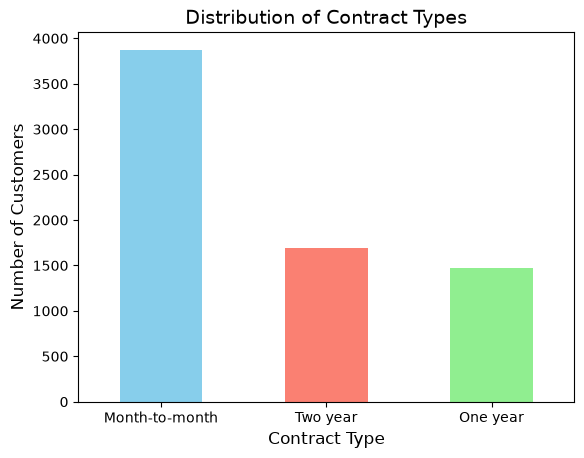

In [14]:
# the graph of contract type distribution

df['Contract'].value_counts().plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'])

# 2. Add titles and labels for clarity
plt.title('Distribution of Contract Types', fontsize=14)
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# 3. Keep the x-axis labels horizontal (optional)
plt.xticks(rotation=0)

# 4. Display the graph
plt.show()

In [15]:
one_year_churned = df[
    (df["Contract"] == "One year") &
    (df["Churn"] == "Yes")
]



yr1_not_churned = df[(df["Contract"] == "One year") & (df["Churn"] == "No")]

two_year_churned = df[
    (df["Contract"] == "Two year") &
    (df["Churn"] == "Yes")
]

yr2_not_churned = df[(df["Contract"] == "Two year") & (df["Churn"] == "No")]






print(one_year_churned)
#print(yr1_not_churned)


      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
173   0691-JVSYA  Female              0     Yes         No      53   
317   2321-OMBXY  Female              0     Yes        Yes      38   
320   5020-ZSTTY  Female              1      No         No      54   
335   4322-RCYMT    Male              0     Yes        Yes      68   
495   8205-OTCHB    Male              0      No         No      22   
...          ...     ...            ...     ...        ...     ...   
6869  5906-CVLHP  Female              0     Yes        Yes      45   
6918  8267-ZNYVZ  Female              0     Yes         No      33   
6972  6664-FPDAC  Female              1      No         No      56   
6996  4174-LPGTI  Female              0     Yes        Yes      41   
7021  1699-HPSBG    Male              0      No         No      12   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
173           Yes                No     Fiber optic             No  ...   
317      

In [16]:
yr1_yes = one_year_churned['Churn'].size
yr1_no = yr1_not_churned['Churn'].size



ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between 'width' with shape (0,) and 'y' with shape (3,).

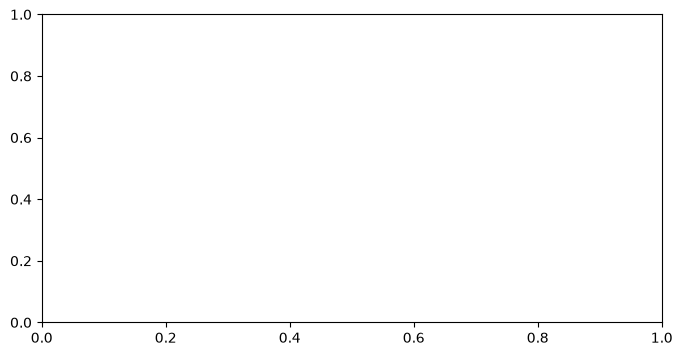

In [17]:
#analysis of contract type against churn

groups = df['Contract'].unique()

yes = []

no = []

y = np.arange(len(groups))

# Create the horizontal stacked bar chart
plt.figure(figsize=(8, 4))

plt.barh(y, yes, color="#2e7d32", label="Yes")
plt.barh(y, no, left=yes, color="#ef5350", label="No")

# Labels and title
plt.yticks(y, groups)
plt.xlabel("Number of people")
plt.title("Churn")
plt.legend()

plt.tight_layout()
plt.show()